# 比亚迪（002594）牛熊 / 震荡指标研究面板 v0.1

依据 GinkgoRoad《牛熊震荡市识别-技术指标深度研究》建立的可复跑图表系统。

**第一版定位：观察，不自动交易。** 趋势指标回答方向，状态指标回答趋势/震荡，波动与量价提供辅助。经典阈值只是参考线，不是经过比亚迪样本验收的买卖规则；本 notebook 不做参数寻优、收益回测或 PASS/FAIL。

数据：`cnstock_kline_day` 前复权日线。所有指标只使用当前及历史行，warmup 保留 NaN；不停靠未来函数，也不把 NaN 填成中性信号。

**交互操作：**在 VS Code Notebook 中选择项目虚拟环境的 Python kernel，重新运行全部单元后，ipympl（widget 后端）会启用交互。移动光标可显示跨子图的交易日竖线；左键点击任意子图会显示或移动 OHLCV 信息卡，点击信息卡右上角的 × 可关闭。静态 PNG 预览只用于保存，不能响应鼠标。

## 0. 配置与数据质检

In [1]:
from pathlib import Path
import sys

import matplotlib
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import Markdown, display

_shell = get_ipython()
INTERACTIVE = _shell is not None and getattr(_shell, 'kernel', None) is not None
matplotlib.use('widget' if INTERACTIVE else 'Agg')

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

ROOT = Path.cwd()
if not (ROOT / 'indicator_research').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from indicator_research.direction import (
    add_direction_states,
    add_donchian_states,
    add_momentum_range_states,
    add_volume_direction_states,
    direction_runs,
)
from indicator_research.divergence import add_momentum_divergences, add_volume_divergences
from indicator_research.volatility import add_volatility_regimes
from indicator_research.interpretation import (
    describe_direction,
    describe_donchian,
    describe_momentum,
    describe_regime,
    describe_volatility,
    describe_volume_confirmation,
)
from indicator_research.interaction import attach_ohlcv_interactions
from indicator_research.regime import add_regime_indicators
from utils.db import read_cnstock_kline_day

STOCK_CODE = '002594'   # 300866, 002594, 300760
START_DATE = None       # 例如 '2020-01-01'；None = 全历史
END_DATE = None         # 排他；None = 数据库最新交易日
DISPLAY_YEARS = 2  # 只限制图表视图；指标仍用完整历史计算

pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 40)
plt.rcParams['font.family'] = ['Noto Sans CJK JP', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110

In [2]:
raw = read_cnstock_kline_day(STOCK_CODE, start=START_DATE, end=END_DATE)
frame = raw.rename(columns={
    'open_price': 'open', 'high_price': 'high',
    'low_price': 'low', 'close_price': 'close',
}).copy()
ts = pd.to_datetime(frame['trade_time'])
if ts.dt.tz is None:
    ts = ts.dt.tz_localize('UTC')
frame['date'] = ts.dt.tz_convert('Asia/Shanghai').dt.tz_localize(None).dt.normalize()
frame = frame.set_index('date').sort_index()

assert len(frame) > 300, '历史长度不足以覆盖 SMA250 与滚动分位数'
assert frame.index.is_unique and frame.index.is_monotonic_increasing
ohlcv = ['open', 'high', 'low', 'close', 'volume']
assert not frame[ohlcv].isna().any().any(), 'OHLCV 存在缺失值'
invalid_ohlc = (
    (frame['high'] < frame[['open', 'close', 'low']].max(axis=1)) |
    (frame['low'] > frame[['open', 'close', 'high']].min(axis=1)) |
    (frame[ohlcv[:4]] <= 0).any(axis=1) |
    (frame['volume'] < 0)
)
assert not invalid_ohlc.any(), f'发现 {int(invalid_ohlc.sum())} 行非法 OHLCV'

qc = pd.DataFrame({
    '项目': ['股票代码', '首个交易日', '最后交易日', '交易日行数', '停牌行数', '重复日期', 'OHLCV 缺失', '非法 OHLCV'],
    '值': [STOCK_CODE, frame.index.min().date(), frame.index.max().date(), len(frame),
          int(frame['suspension'].sum()), int(frame.index.duplicated().sum()),
          int(frame[ohlcv].isna().sum().sum()), int(invalid_ohlc.sum())],
})
display(qc)
print('停牌行保留在交易日序列中；量价图解读时需注意其零成交量/无价格变化的影响。')

full_df = add_regime_indicators(frame)
indicator_count = len(full_df.columns) - len(frame.columns)
full_df = add_direction_states(full_df)
full_df = add_donchian_states(full_df)
full_df = add_momentum_range_states(full_df)
full_df = add_momentum_divergences(full_df)
full_df = add_volume_direction_states(full_df)
full_df = add_volume_divergences(full_df)
full_df = add_volatility_regimes(full_df)
df = full_df[full_df.index >= full_df.index.max() - pd.DateOffset(years=DISPLAY_YEARS)].copy()
print(f'完整历史：{len(full_df)} 行，仅用于指标计算；图表视图：近 {DISPLAY_YEARS} 年，{df.index.min().date()} → {df.index.max().date()}')
print(f'指标列数：{indicator_count}')
df = df.reset_index(names='date')
recent = df

,项目,值
0,股票代码,300760
1,首个交易日,2018-10-16
2,最后交易日,2026-11-06
3,交易日行数,1949
4,停牌行数,0
5,重复日期,0
6,OHLCV 缺失,0
7,非法 OHLCV,0


停牌行保留在交易日序列中；量价图解读时需注意其零成交量/无价格变化的影响。
完整历史：1949 行，仅用于指标计算；图表视图：近 2 年，2024-11-06 → 2026-11-06
指标列数：36


## 1. 方向层：长均线、MACD、唐奇安通道

所有图的横轴按实际交易日等距排列，周末和节假日不占位；刻度仍显示真实交易日期。

- 长均线牛市参考：`close ≥ SMA200` 且 `SMA200 slope20 > 0`；熊市参考：`close < SMA200` 且斜率 < 0；其余为中性/过渡。
- MACD：DIF = EMA12 − EMA26，DEA = DIF 的 EMA9，柱 = 2×(DIF−DEA)。
- 方向图按每日收盘后的状态着色：红色为牛市参考、绿色为熊市参考、灰色为中性/过渡；MACD 以 DIF > DEA 为牛市参考、DIF < DEA 为熊市参考。背景延续至状态改变，三角标记只出现在进入牛熊状态的交易日；首段若早已开始，不补标起点。
- 唐奇安通道为 20 日最高/最低价，展示价格所处区间；当前图不将突破直接转成交易动作。
- 唐奇安背景使用通道自身的突破状态：收盘突破前一日上轨进入红色牛市参考，突破前一日下轨进入绿色熊市参考，并持续至反向突破；同向重复突破不重新打点。

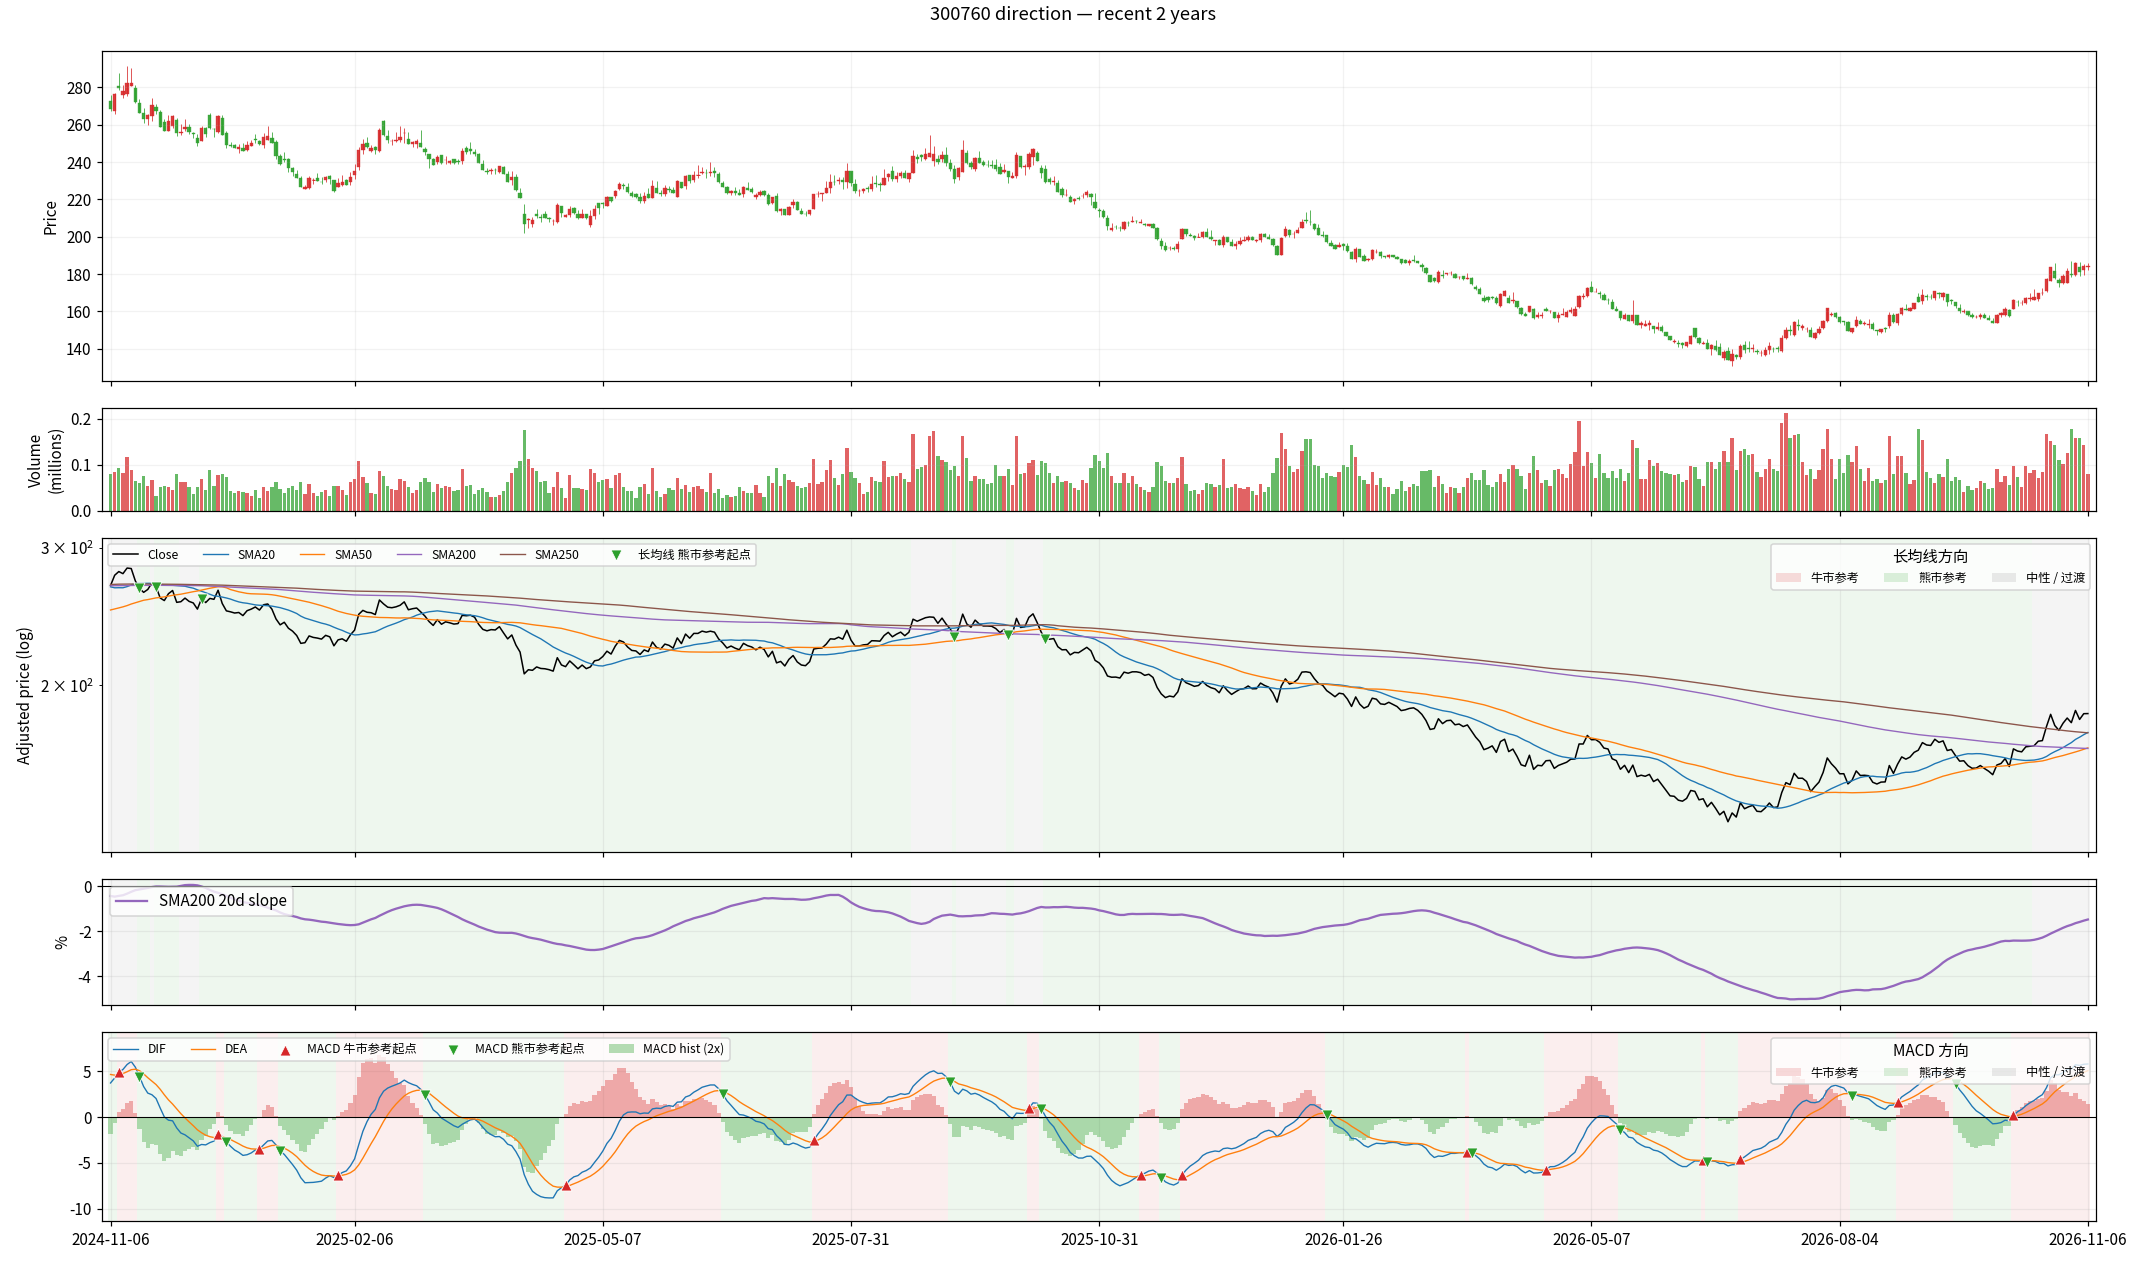

**方向层状态解读｜截至 2026-11-06**

- **长期方向：长期方向分歧 / 过渡。** 收盘价 ≥ SMA200 且 SMA200 的 20 日斜率 > 0 为多头参考；收盘价 < SMA200 且斜率 < 0 为空头参考。当前收盘 184.15，相对 SMA200 为 +10.80%，斜率 -1.48%，价格位置与长均线斜率没有同向确认。
- **MACD：零轴上方的正向动量。** DIF = 5.791，DEA = 5.062，柱 = 1.458；DIF > DEA，短期动量改善。DIF 的零轴位置用于区分趋势背景，DIF 与 DEA 的关系用于观察短期动量。
- **综合解读：**长期方向与 MACD 未形成同向确认，按过渡或分歧状态观察。 SMA20/50/250 作为不同周期的价格位置参照，不额外投票。

*以上为指标状态说明，经典阈值仅作观察参考，不构成独立交易信号。*

In [3]:
def make_indicator_panel(data, row_heights):
    fig, axes = plt.subplots(
        len(row_heights) + 2, 1, figsize=(19.5, 5.5 + 2.0 * len(row_heights)), sharex=True,
        gridspec_kw={'height_ratios': [2.1, .65, *row_heights]})
    candle_ax, volume_ax = axes[:2]
    x = data.index.to_numpy()
    dates = pd.to_datetime(data['date'])
    opens, closes = data['open'], data['close']
    colors = np.where(closes >= opens, '#d62728', '#2ca02c')
    body = (closes - opens).abs()
    candle_ax.vlines(x, data['low'], data['high'], colors=colors, linewidths=.55, alpha=.9)
    candle_ax.bar(x, body, bottom=np.minimum(opens, closes), width=.8,
                  color=colors, edgecolor=colors, linewidth=.25, alpha=.9)
    doji = body <= 1e-12
    if doji.any():
        candle_ax.hlines(closes[doji], x[doji] - .4, x[doji] + .4,
                         colors=colors[doji], linewidths=.6)
    candle_ax.set_ylabel('Price')
    candle_ax.grid(alpha=.16)
    volume_ax.bar(x, data['volume'] / 1e6, width=.8, color=colors, alpha=.72)
    volume_ax.set_ylabel('Volume\n(millions)')
    volume_ax.grid(alpha=.16)
    tick_positions = np.unique(np.linspace(0, len(data) - 1, num=min(9, len(data)), dtype=int))
    volume_ax.set_xticks(tick_positions)
    volume_ax.set_xticklabels(dates.iloc[tick_positions].dt.strftime('%Y-%m-%d'))
    volume_ax.set_xlim(-2, len(data) + 1)
    return fig, axes[2:]

def show_figure(fig, data):
    if INTERACTIVE:
        attach_ohlcv_interactions(fig, data)
    plt.show()

DIRECTION_COLORS = {'bull': '#d62728', 'bear': '#2ca02c', 'neutral': '#7f7f7f'}
DIRECTION_LABELS = {'bull': '牛市参考', 'bear': '熊市参考', 'neutral': '中性 / 过渡'}

def shade_direction(ax, states):
    for state, start, end in direction_runs(states):
        if state == 'warmup':
            continue
        ax.axvspan(start - .5, end - .5, facecolor=DIRECTION_COLORS[state],
                   alpha=.08, linewidth=0, zorder=0)
    ax.set_axisbelow(True)

def direction_legend_handles(states=('bull', 'bear', 'neutral')):
    return [
        Patch(facecolor=DIRECTION_COLORS[state], alpha=.16, edgecolor='none', label=DIRECTION_LABELS[state])
        for state in states
    ]

def mark_direction_points(ax, data, signal_column, y_column, label_prefix):
    for state, marker in [('bull', '^'), ('bear', 'v')]:
        mask = data[signal_column].eq(state).fillna(False).to_numpy(dtype=bool)
        selected = data.index[mask]
        if selected.empty:
            continue
        y = data.loc[selected, y_column].to_numpy(dtype=float)
        color = DIRECTION_COLORS[state]
        ax.scatter(selected, y, s=52, marker=marker, facecolor=color, edgecolor='white',
                   linewidth=.55, zorder=5, label=f'{label_prefix}{DIRECTION_LABELS[state]}起点')

def plot_direction(data, title):
    fig, axes = make_indicator_panel(data, [2.0, 0.8, 1.2])
    ax = axes[0]
    shade_direction(ax, data['long_direction'])
    ax.plot(data.index, data['close'], color='black', lw=1.0, label='Close')
    for n, color in [(20, '#1f77b4'), (50, '#ff7f0e'), (200, '#9467bd'), (250, '#8c564b')]:
        ax.plot(data.index, data[f'sma{n}'], lw=0.9, label=f'SMA{n}', color=color)
    mark_direction_points(ax, data, 'long_signal', 'close', '长均线 ')
    ax.set_yscale('log'); ax.set_ylabel('Adjusted price (log)'); ax.margins(y=.12)
    price_legend = ax.legend(ncol=7, fontsize=8, loc='upper left')
    ax.add_artist(price_legend)
    ax.legend(handles=direction_legend_handles(), ncol=3, fontsize=8, loc='upper right', title='长均线方向')
    ax.grid(alpha=.2)

    shade_direction(axes[1], data['long_direction'])
    axes[1].plot(data.index, data['sma200_slope20'] * 100, color='#9467bd', label='SMA200 20d slope')
    axes[1].axhline(0, color='black', lw=.7)
    axes[1].set_ylabel('%'); axes[1].legend(loc='upper left'); axes[1].grid(alpha=.2)

    ax = axes[2]
    shade_direction(ax, data['macd_direction'])
    ax.plot(data.index, data['dif'], label='DIF', lw=.9)
    ax.plot(data.index, data['dea'], label='DEA', lw=.9)
    colors = np.where(data['macd_hist'].fillna(0) >= 0, '#d62728', '#2ca02c')
    ax.bar(data.index, data['macd_hist'], color=colors, width=1.0, alpha=.35, label='MACD hist (2x)')
    mark_direction_points(ax, data, 'macd_signal', 'dif', 'MACD ')
    ax.axhline(0, color='black', lw=.7); ax.margins(y=.16)
    macd_legend = ax.legend(ncol=5, fontsize=8, loc='upper left')
    ax.add_artist(macd_legend)
    ax.legend(handles=direction_legend_handles(), ncol=3, fontsize=8, loc='upper right', title='MACD 方向')
    ax.grid(alpha=.2)
    fig.suptitle(title, y=.995); fig.tight_layout()
    show_figure(fig, data)
    display(Markdown(describe_direction(data)))

plot_direction(recent, f'{STOCK_CODE} direction — recent {DISPLAY_YEARS} years')

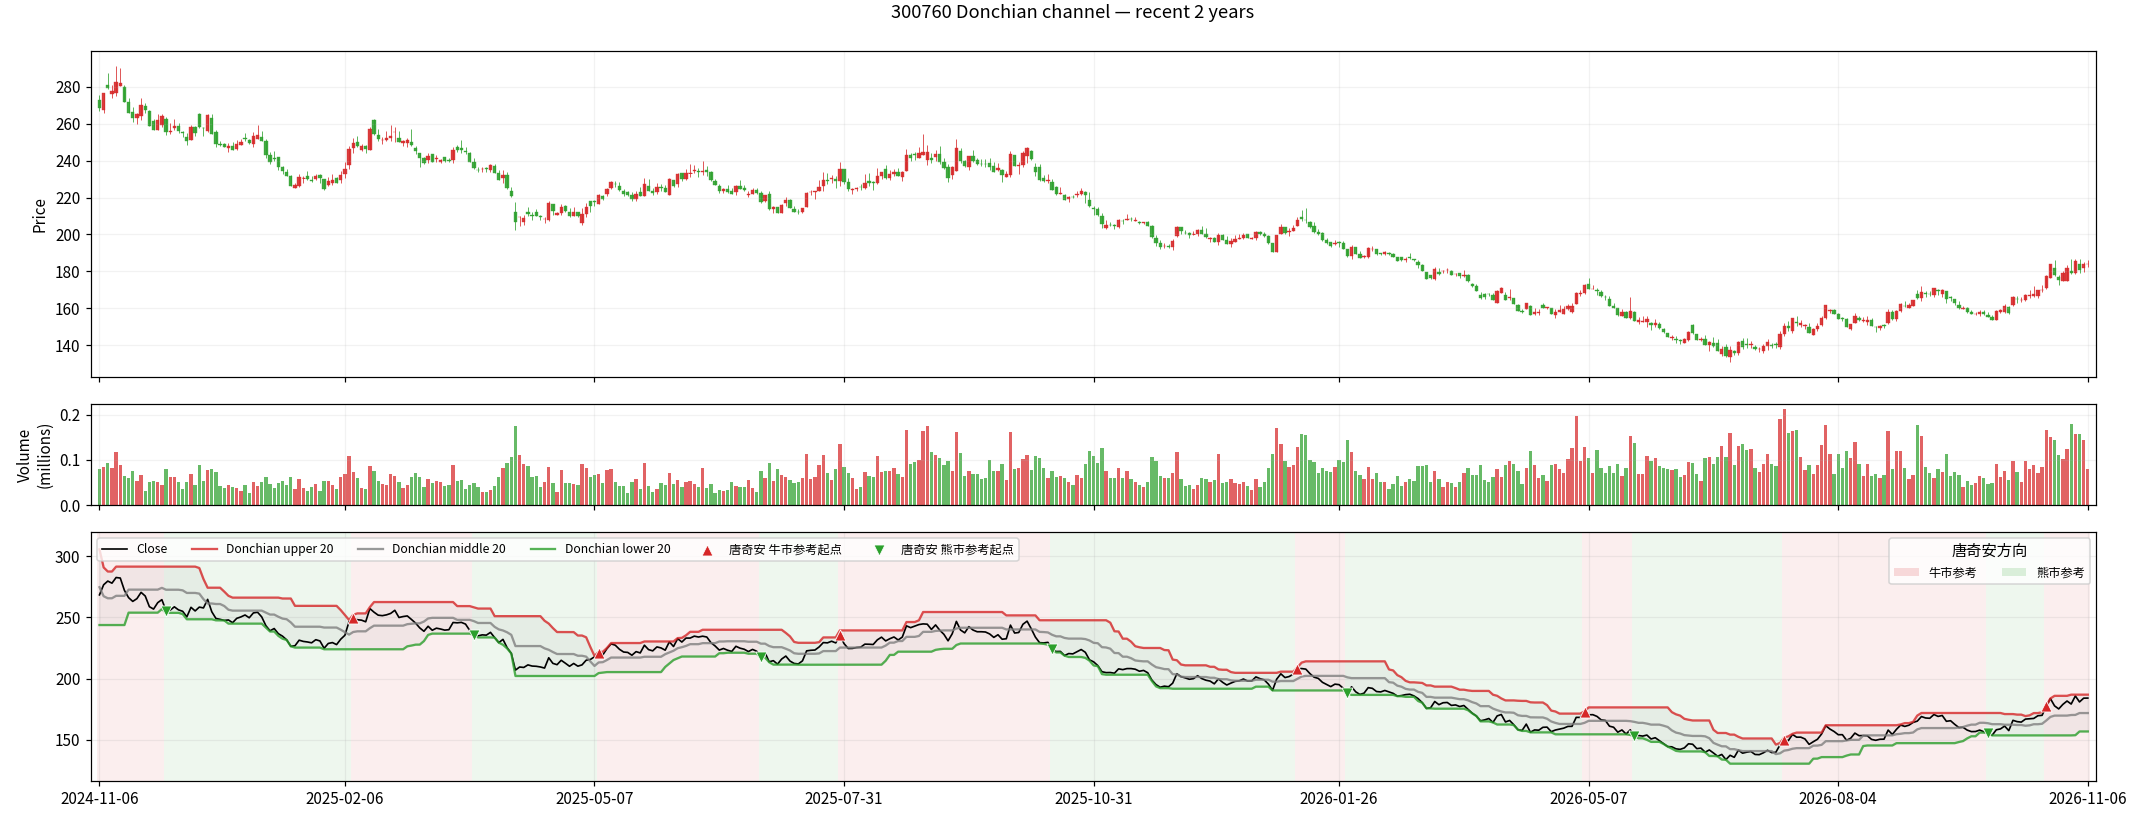

**唐奇安通道状态解读｜截至 2026-11-06**

- **当日突破状态：通道内运行。** 判据使用前一交易日通道，避免把当日高低点纳入比较基准；收盘 > 前一日上轨为向上突破观察，收盘 < 前一日下轨为向下突破观察。收盘价尚未越出前一交易日的 20 日通道。
- **图中方向区间：牛市参考。** 背景状态在突破后持续至反向突破，与当日是否仍在通道内是两个不同维度；同向重复突破不重新标记起点。
- **区间位置：**当前通道为 156.93—186.95，收盘位于区间的 90.7% 位置；0% 对应下轨，100% 对应上轨。
- **解读：**当前主要是区间位置信息；接近上沿或下沿本身不保证突破或反转。通道描述近期价格区间，不单独预测趋势方向。

*以上为指标状态说明，经典阈值仅作观察参考，不构成独立交易信号。*

In [4]:
def plot_donchian(data, title):
    fig, axes = make_indicator_panel(data, [1.6])
    ax = axes[0]
    shade_direction(ax, data['donchian_direction'])
    ax.plot(data.index, data['close'], color='black', lw=1.1, label='Close')
    ax.plot(data.index, data['donchian_upper20'], label='Donchian upper 20', color='#d62728', alpha=.8)
    ax.plot(data.index, data['donchian_middle20'], label='Donchian middle 20', color='#7f7f7f', alpha=.8)
    ax.plot(data.index, data['donchian_lower20'], label='Donchian lower 20', color='#2ca02c', alpha=.8)
    ax.fill_between(data.index, data['donchian_lower20'], data['donchian_upper20'], color='grey', alpha=.08)
    mark_direction_points(ax, data, 'donchian_signal', 'close', '唐奇安 ')
    ax.margins(y=.08)
    channel_legend = ax.legend(ncol=6, fontsize=8, loc='upper left')
    ax.add_artist(channel_legend)
    ax.legend(handles=direction_legend_handles(('bull', 'bear')), ncol=2, fontsize=8,
              loc='upper right', title='唐奇安方向')
    fig.suptitle(title, y=.995)
    ax.grid(alpha=.2); fig.tight_layout()
    show_figure(fig, data)
    display(Markdown(describe_donchian(data)))

plot_donchian(recent, f'{STOCK_CODE} Donchian channel — recent {DISPLAY_YEARS} years')

## 2. 动量层：RSI、KDJ、ROC、CCI

RSI 的 50 中轴比“70 就卖、30 就买”更适合状态观察；强趋势中 RSI/KDJ 可以长期钝化。ROC 是 20 日价格变化率，CCI 的 ±100 是统计异常参考，不是自动反转点。

紫色背景为动量震荡观察区：RSI14 ∈ [30, 70]、K 与 D ∈ [20, 80]、CCI20 ∈ [−100, +100] 同时成立，任一条件失效即结束；ROC 不参与区间判定。非极端动量不等同于价格必然横盘，仍需结合 ADX/CHOP 确认市场状态。

背离标记使用左右各 2 根 K 线确认摆动点：价格形成更低低点而指标形成更高低点为底背离（红色上三角），价格形成更高高点而指标形成更低高点为顶背离（绿色下三角）。比较的摆动点间隔为 5—60 个交易日，KDJ 使用 K 值；标记画在右侧第 2 根 K 线的确认日，不回填到过去，也不预示必然反转。

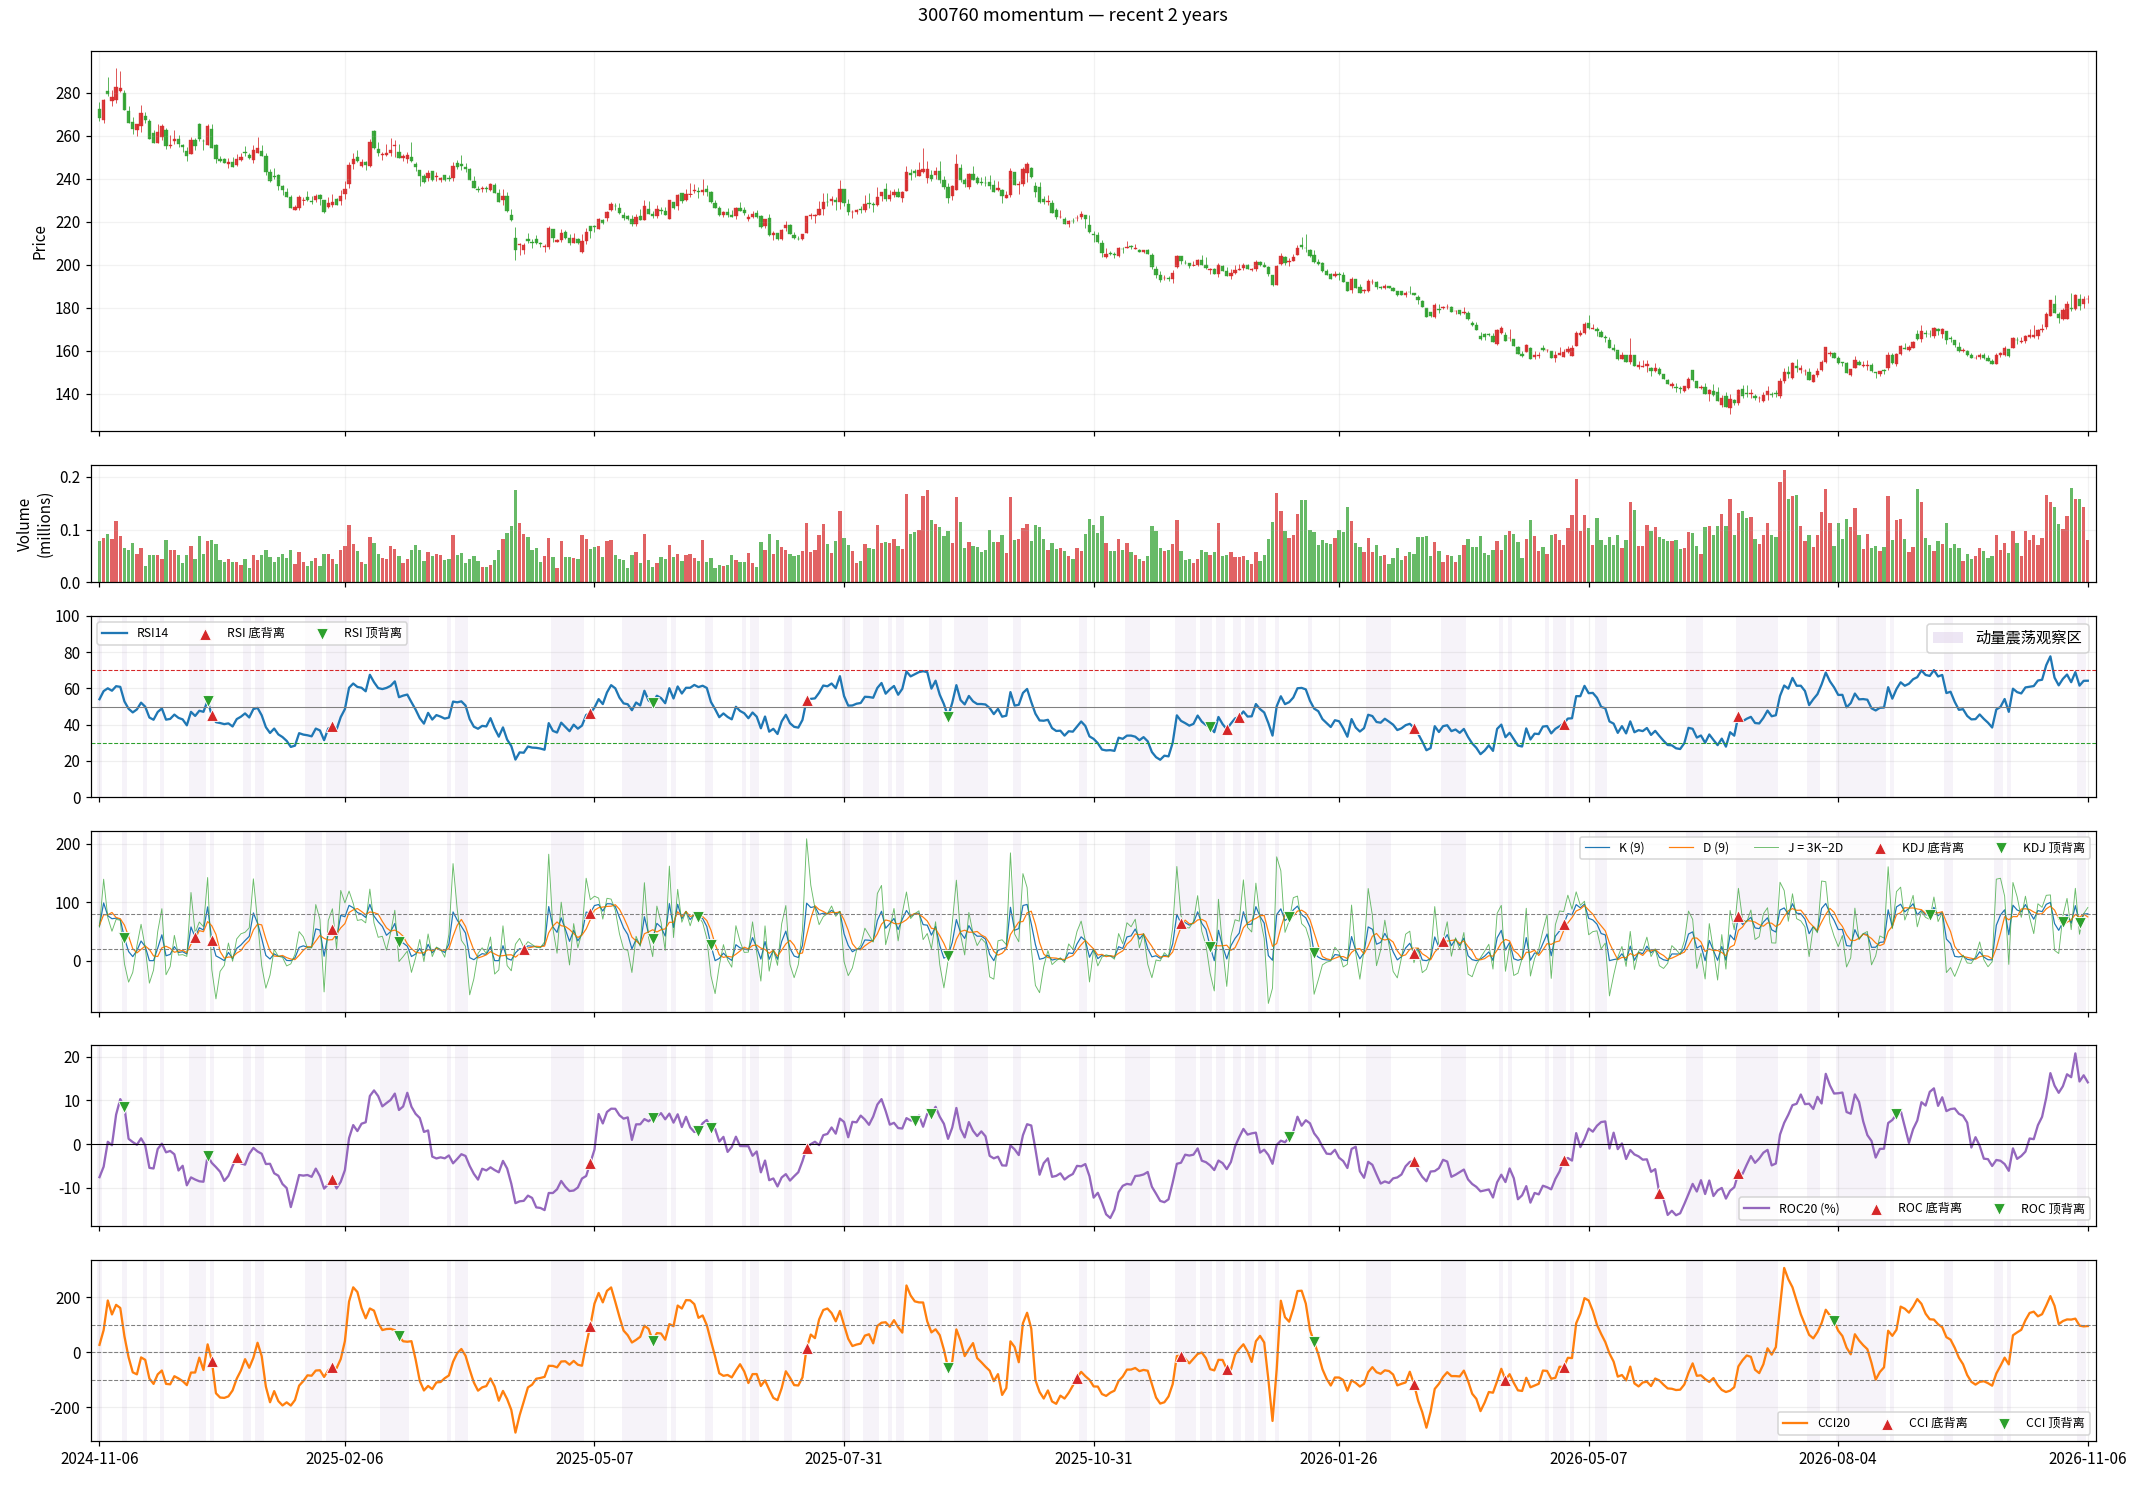

**动量层状态解读｜截至 2026-11-06**

- **RSI14：中性偏强（64.24）。** ≥ 70 为超买参考，≤ 30 为超卖参考；其余区间再用 50 中轴区分偏强或偏弱。极值表示动量温度，不自动意味着反转。
- **KDJ：非极端区；K > D，短期动量向上。** K = 80.11，D = 74.76，J = 90.82；K、D 均 ≥ 80 为高位参考，均 ≤ 20 为低位参考，强趋势中可能持续钝化。
- **ROC20：正动量（+14.15%）。** 以 0 为判据，收盘价高于 20 个交易日前。
- **CCI20：常态区内偏强（95.25）。** ≥ +100 或 ≤ −100 为统计极端参考，−100 至 +100 内再用 0 轴观察强弱。
- **震荡观察：当前不处于动量震荡观察区。** 紫色区间要求 RSI14 在 30—70、K 与 D 在 20—80、CCI20 在 −100—+100 内同时成立；ROC 不参与判定，非极端动量不等同于价格必然横盘。
- **综合解读：**ROC 为正且 K > D，短期动量偏改善。超买不等于立即下跌，超卖也不等于立即上涨。

*以上为指标状态说明，经典阈值仅作观察参考，不构成独立交易信号。*

In [5]:
MOMENTUM_RANGE_COLOR = '#9467bd'

def shade_momentum_range(ax, states):
    for state, start, end in direction_runs(states):
        if state != 'range':
            continue
        ax.axvspan(start - .5, end - .5, facecolor=MOMENTUM_RANGE_COLOR,
                   alpha=.08, linewidth=0, zorder=0)
    ax.set_axisbelow(True)

def mark_divergences(ax, data, prefix, y_column, label_prefix):
    styles = [
        ('bullish', '^', DIRECTION_COLORS['bull'], '底背离'),
        ('bearish', 'v', DIRECTION_COLORS['bear'], '顶背离'),
    ]
    for direction, marker, color, label in styles:
        mask = data[f'{prefix}_{direction}_divergence'].to_numpy(dtype=bool)
        selected = data.index[mask]
        if selected.empty:
            continue
        y = data.loc[selected, y_column].to_numpy(dtype=float)
        ax.scatter(selected, y, s=60, marker=marker, facecolor=color, edgecolor='white',
                   linewidth=.6, zorder=6, label=f'{label_prefix}{label}')

fig, axes = make_indicator_panel(df, [1.0, 1.0, 1.0, 1.0])
for ax in axes:
    shade_momentum_range(ax, df['momentum_range'])
axes[0].plot(df.index, df['rsi14'], color='#1f77b4', label='RSI14')
for level, style in [(70, '--'), (50, '-'), (30, '--')]:
    axes[0].axhline(level, color='grey' if level == 50 else '#d62728' if level == 70 else '#2ca02c', lw=.7, ls=style)
mark_divergences(axes[0], df, 'rsi', 'rsi14', 'RSI ')
axes[0].set_ylim(0, 100)
rsi_legend = axes[0].legend(ncol=3, fontsize=8, loc='upper left')
axes[0].add_artist(rsi_legend)
axes[0].legend(handles=[Patch(facecolor=MOMENTUM_RANGE_COLOR, alpha=.16, edgecolor='none',
                             label='动量震荡观察区')], loc='upper right')
axes[0].grid(alpha=.2)

axes[1].plot(df.index, df['kdj_k'], label='K (9)', lw=.8)
axes[1].plot(df.index, df['kdj_d'], label='D (9)', lw=.8)
axes[1].plot(df.index, df['kdj_j'], label='J = 3K−2D', lw=.6, alpha=.7)
for level in [20, 80]: axes[1].axhline(level, color='grey', lw=.7, ls='--')
mark_divergences(axes[1], df, 'kdj', 'kdj_k', 'KDJ ')
axes[1].legend(ncol=5, fontsize=8); axes[1].grid(alpha=.2)

axes[2].plot(df.index, df['roc20'], color='#9467bd', label='ROC20 (%)')
axes[2].axhline(0, color='black', lw=.7)
mark_divergences(axes[2], df, 'roc', 'roc20', 'ROC ')
axes[2].legend(ncol=3, fontsize=8); axes[2].grid(alpha=.2)

axes[3].plot(df.index, df['cci20'], color='#ff7f0e', label='CCI20')
for level in [-100, 0, 100]: axes[3].axhline(level, color='grey', lw=.7, ls='--')
mark_divergences(axes[3], df, 'cci', 'cci20', 'CCI ')
axes[3].legend(ncol=3, fontsize=8); axes[3].grid(alpha=.2)
fig.suptitle(f'{STOCK_CODE} momentum — recent {DISPLAY_YEARS} years', y=.995); fig.tight_layout()
show_figure(fig, df)
display(Markdown(describe_momentum(df)))

## 3. 波动层：布林带、BandWidth、NATR

BandWidth = (上轨−下轨)/中轨；`rank126` 是其在过去 126 个交易日中的滚动分位，低于 0.10 仅表示波动压缩（Squeeze 参考），不预测突破方向。NATR = ATR14/close，以百分比显示。

波动状态着色：%B > 1 或 < 0 且 BandWidth 较前一日上升为趋势扩张参考（橙色）；%B ∈ [0, 1] 且 rank126 ≤ 0.10 为震荡/压缩参考（蓝色）；其余为灰色过渡。BandWidth 分位面板上的圆点表示状态起点，X 表示状态失效的终点确认日。趋势/震荡仅为波动状态参考，不区分涨跌方向。

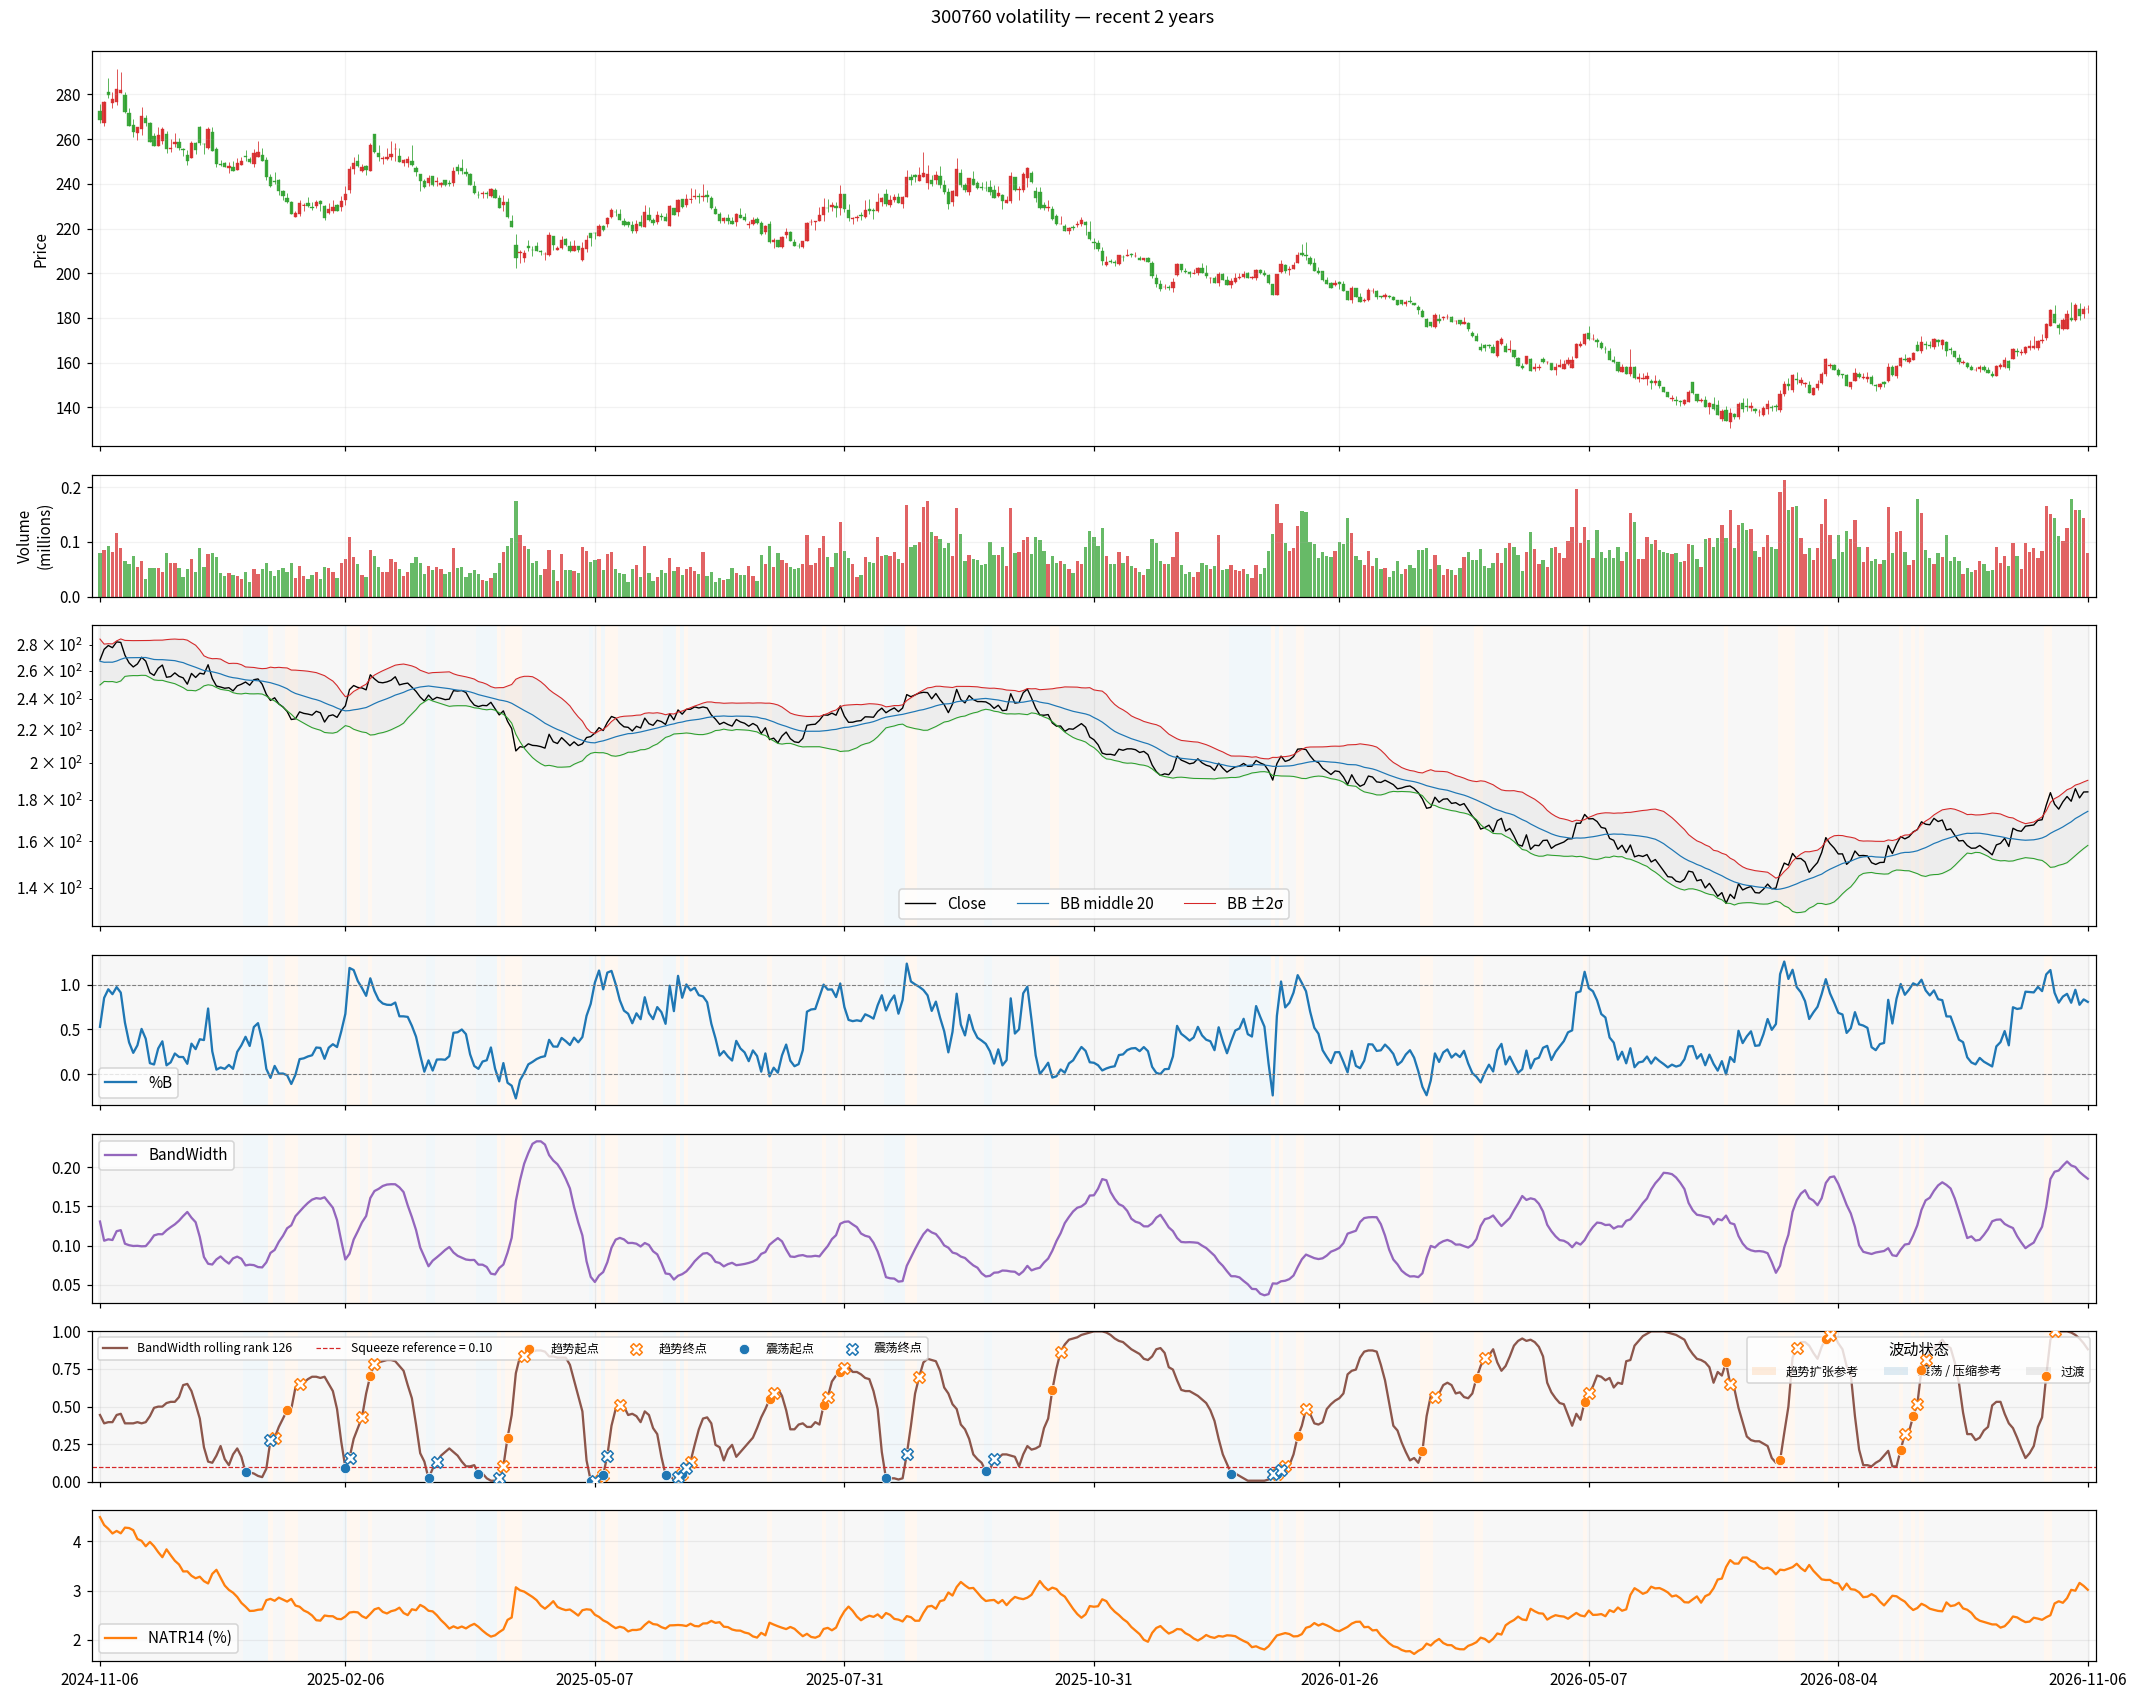

**波动层状态解读｜截至 2026-11-06**

- **价格位置：布林带内。** 收盘 184.15，%B = 0.808；%B > 1 表示收盘在上轨之外，%B < 0 表示在下轨之外，0—1 表示带内。
- **带宽状态：中间分位。** BandWidth = 18.53%，126 日滚动分位 = 88.1%；≤ 10% 为压缩参考，≥ 90% 为高分位扩张描述，其余为中间分位。
- **相对波动：NATR14 = 3.02%。** NATR = ATR14 / 收盘价；数值越高表示相对波动越大，没有固定牛熊阈值，也不指示方向。
- **图中波动状态：中性 / 过渡。** 带外且带宽扩大为橙色趋势扩张参考；带内且带宽分位 ≤ 10% 为蓝色震荡 / 压缩参考。圆点为起点，X 为状态失效的终点确认日；趋势状态不区分涨跌方向。
- **综合解读：**价格仍在带内，结合带宽分位观察波动扩张或收缩，不据此给出涨跌方向。

*以上为指标状态说明，经典阈值仅作观察参考，不构成独立交易信号。*

In [6]:
VOLATILITY_COLORS = {'trend': '#ff7f0e', 'range': '#1f77b4', 'neutral': '#7f7f7f'}
VOLATILITY_LABELS = {'trend': '趋势扩张参考', 'range': '震荡 / 压缩参考', 'neutral': '过渡'}

def shade_volatility_regimes(ax, states):
    for state, start, end in direction_runs(states):
        if state == 'warmup':
            continue
        ax.axvspan(start - .5, end - .5, facecolor=VOLATILITY_COLORS[state],
                   alpha=.06, linewidth=0, zorder=0)
    ax.set_axisbelow(True)

def volatility_legend_handles():
    return [
        Patch(facecolor=VOLATILITY_COLORS[state], alpha=.14, edgecolor='none', label=VOLATILITY_LABELS[state])
        for state in ['trend', 'range', 'neutral']
    ]

def mark_volatility_events(ax, data):
    styles = [
        ('trend', 'start', '趋势起点'),
        ('trend', 'end', '趋势终点'),
        ('range', 'start', '震荡起点'),
        ('range', 'end', '震荡终点'),
    ]
    for state, event, label in styles:
        mask = data[f'volatility_{state}_{event}'].to_numpy(dtype=bool)
        selected = data.index[mask]
        if selected.empty:
            continue
        y = data.loc[selected, 'bb_width_rank126'].to_numpy(dtype=float)
        color = VOLATILITY_COLORS[state]
        is_start = event == 'start'
        ax.scatter(selected, y, s=46 if is_start else 58, marker='o' if is_start else 'X',
                   facecolor=color if is_start else 'white', edgecolor='white' if is_start else color,
                   linewidth=.5 if is_start else 1.0, zorder=6, label=label)

fig, axes = make_indicator_panel(df, [1.6, .8, .9, .8, .8])
for ax in axes:
    shade_volatility_regimes(ax, df['volatility_regime'])
axes[0].plot(df.index, df['close'], color='black', lw=.9, label='Close')
axes[0].plot(df.index, df['bb_middle'], label='BB middle 20', lw=.8)
axes[0].plot(df.index, df['bb_upper'], label='BB ±2σ', color='#d62728', lw=.7)
axes[0].plot(df.index, df['bb_lower'], color='#2ca02c', lw=.7)
axes[0].fill_between(df.index, df['bb_lower'], df['bb_upper'], color='grey', alpha=.08)
axes[0].set_yscale('log'); axes[0].legend(ncol=4); axes[0].grid(alpha=.2)

axes[1].plot(df.index, df['bb_pct_b'], label='%B', color='#1f77b4')
for level in [0, 1]: axes[1].axhline(level, color='grey', lw=.7, ls='--')
axes[1].legend(); axes[1].grid(alpha=.2)

axes[2].plot(df.index, df['bb_width'], label='BandWidth', color='#9467bd')
axes[2].legend(); axes[2].grid(alpha=.2)

axes[3].plot(df.index, df['bb_width_rank126'], label='BandWidth rolling rank 126', color='#8c564b')
axes[3].axhline(.10, color='#d62728', ls='--', lw=.8, label='Squeeze reference = 0.10')
mark_volatility_events(axes[3], df)
axes[3].set_ylim(0, 1)
rank_legend = axes[3].legend(ncol=6, fontsize=8, loc='upper left')
axes[3].add_artist(rank_legend)
axes[3].legend(handles=volatility_legend_handles(), ncol=3, fontsize=8, loc='upper right', title='波动状态')
axes[3].grid(alpha=.2)

axes[4].plot(df.index, df['natr14'], label='NATR14 (%)', color='#ff7f0e')
axes[4].legend(); axes[4].grid(alpha=.2)
fig.suptitle(f'{STOCK_CODE} volatility — recent {DISPLAY_YEARS} years', y=.995); fig.tight_layout()
show_figure(fig, df)
display(Markdown(describe_volatility(df)))

## 4. 量价确认层：OBV、MFI、量比

OBV 是累计量，绝对水平依赖序列起点，只看形态和背离，不做跨股票数值比较。MFI 是量价版 RSI；量比 = 当日成交量/20 日均量。A 股停牌、涨跌停和除权处理都会影响量能解释。

量价方向背景使用本层自身的 20 日判据：价格与 OBV 同时上升为红色牛市参考，同时下降为绿色熊市参考，其余为灰色量价分歧/过渡。背景持续至状态改变，价格子图的三角只标记切换日，首段不补历史起点；它不复制长均线或 MACD 的方向。

OBV 与 MFI 背离使用和动量层相同的规则：左右各 2 根 K 线确认摆动点，摆动点间隔 5—60 个交易日。价格更低低点而指标更高低点为底背离（红色上三角），价格更高高点而指标更低高点为顶背离（绿色下三角）。标记位于确认日，不回填到过去，也不预示必然反转。量比仅观察量能强弱，不单独判断背离。

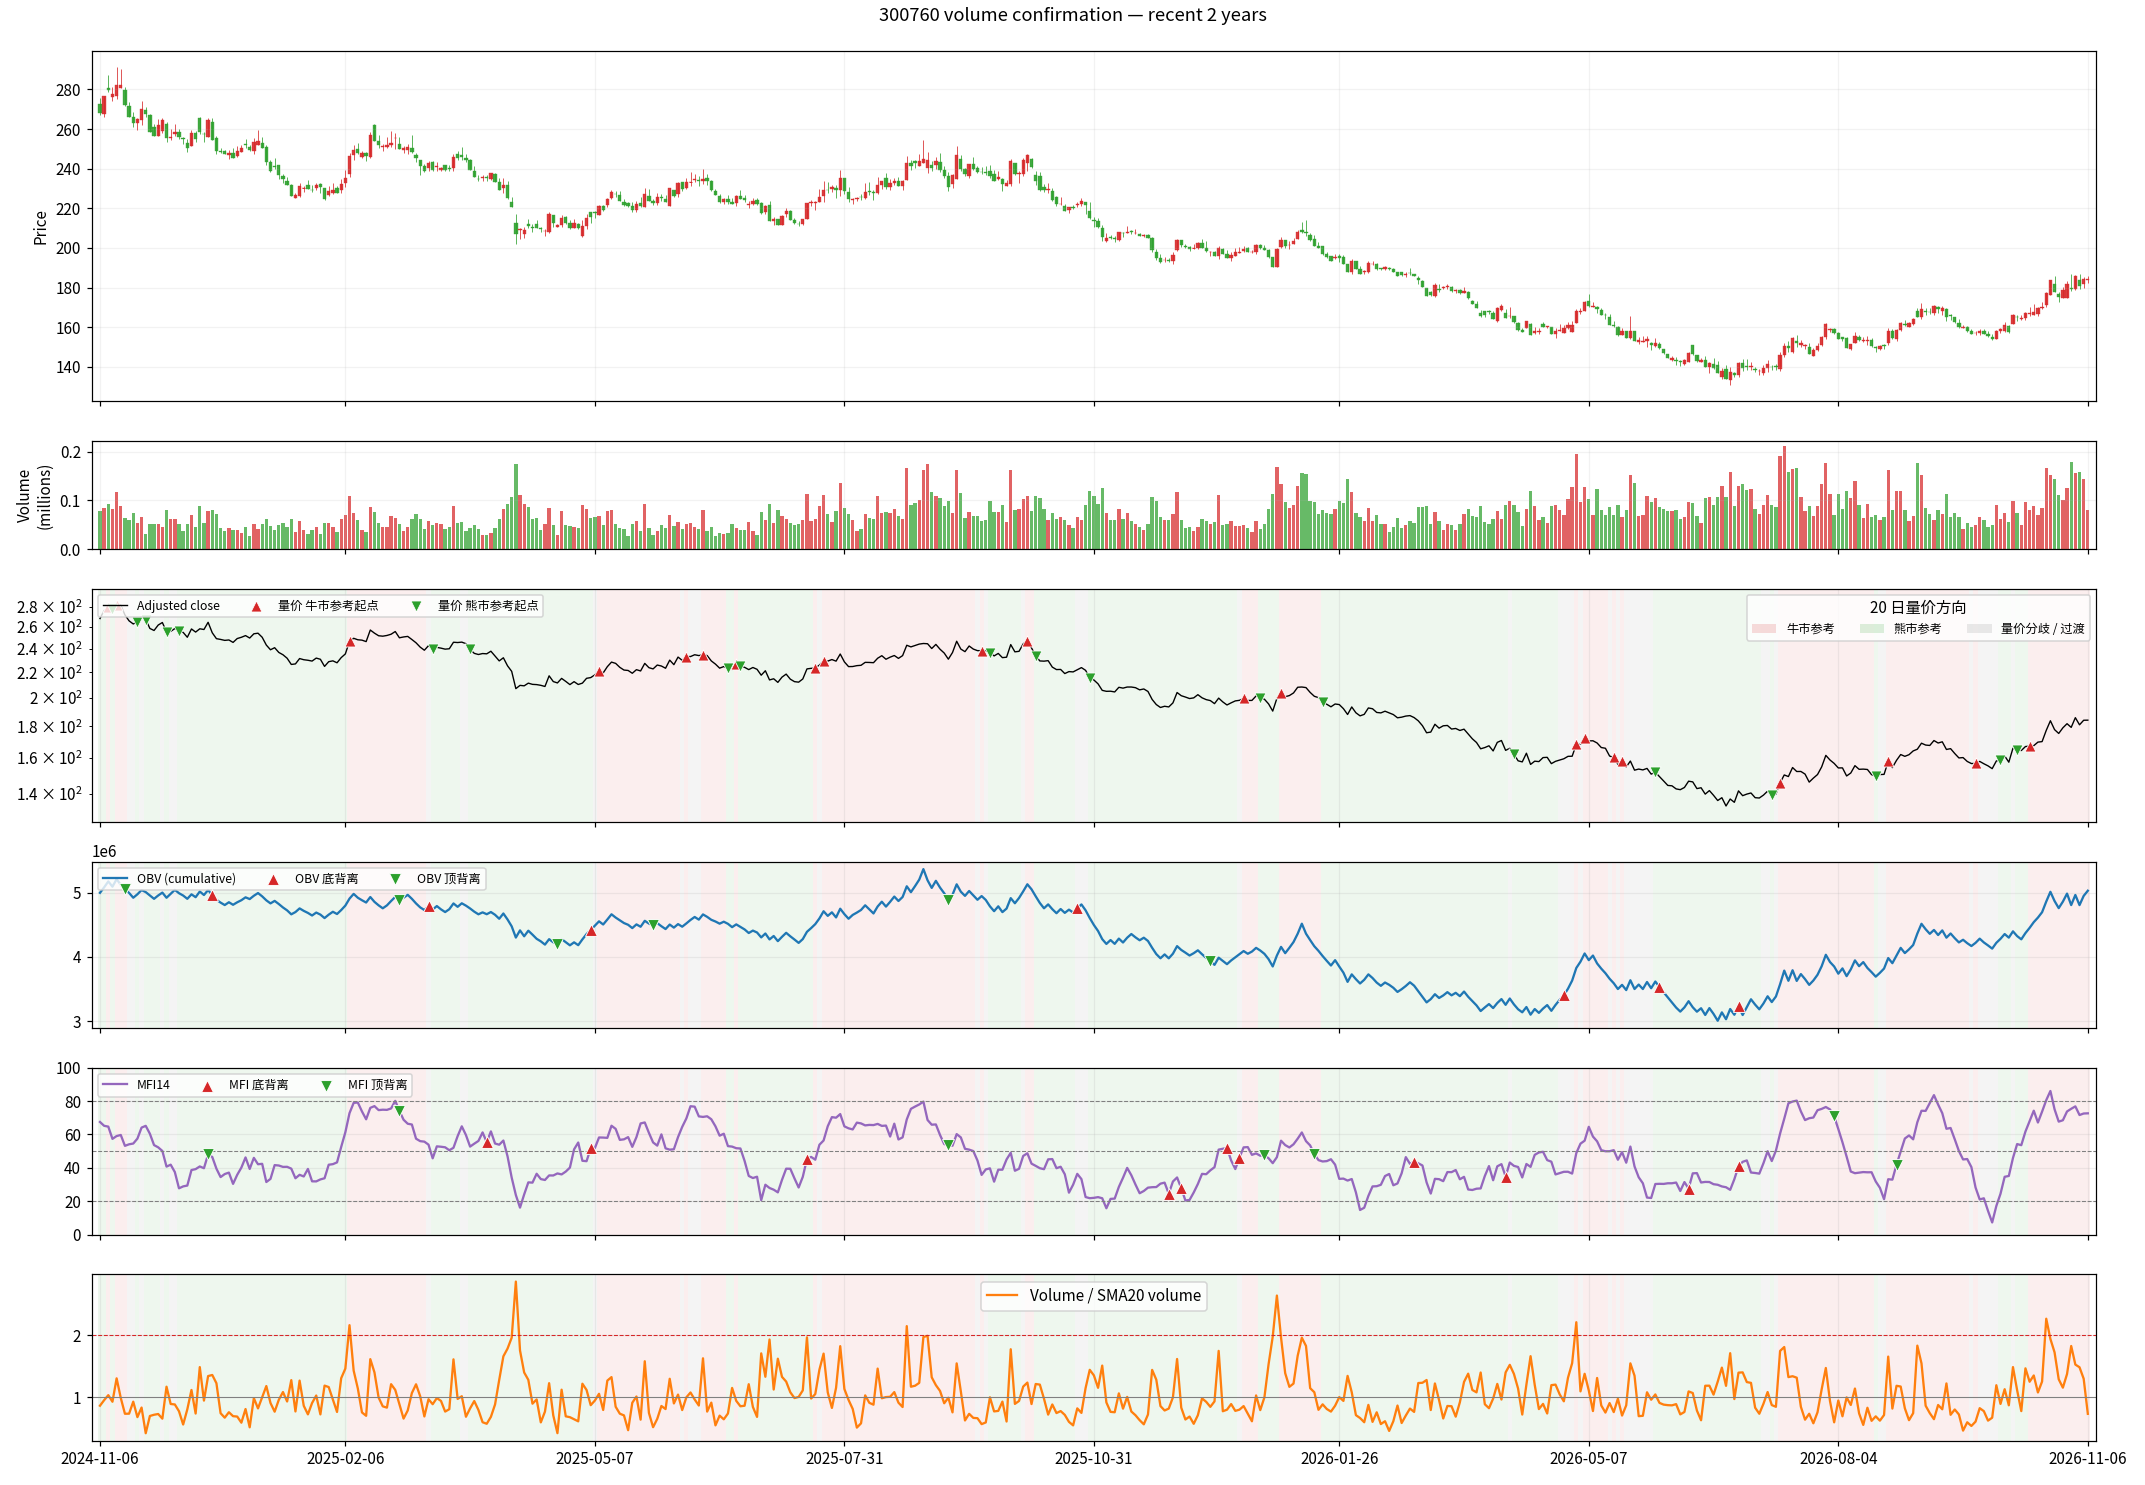

**量价确认层状态解读｜截至 2026-11-06**

- **20 日量价配合：量价同向偏强。** 价格变化 +14.15%，OBV 相较 20 个交易日前上升；20 日价格上涨，OBV 也上升，累积量价方向相互确认。OBV 的绝对水平不用于跨股票比较。
- **MFI14：量价偏强区（72.69）。** ≥ 80 为超买参考，≤ 20 为超卖参考；其余区间以 50 观察量价强弱，不把 MFI 直接解释为确定性资金流入或流出。
- **量能状态：相对缩量。** 当日成交量 / 20 日均量 = 0.73；≥ 2 为显著放量，1—2 为温和放量，< 1 为相对缩量。放量只表示活跃度提高，仍需结合价格方向。
- **图中牛熊区间：牛市参考。** 红色要求 20 日价格与 OBV 同时上升，绿色要求两者同时下降，其余为灰色分歧/过渡；三角标记状态切换日，首段不补历史起点。
- **近 20 个交易日新确认的背离：**OBV 底背离 0 次、顶背离 0 次；MFI 底背离 0 次、顶背离 0 次。底背离为红色上三角，顶背离为绿色下三角；左右各 2 根 K 线确认摆动点，标记在确认日而非过去的摆动点，不预示必然反转。量比不单独判断背离。

*以上为指标状态说明，经典阈值仅作观察参考，不构成独立交易信号。*

In [7]:
fig, axes = make_indicator_panel(df, [1.4, 1.0, 1.0, 1.0])
for ax in axes:
    shade_direction(ax, df['volume_direction'])
axes[0].plot(df.index, df['close'], color='black', lw=.9, label='Adjusted close')
mark_direction_points(axes[0], df, 'volume_signal', 'close', '量价 ')
axes[0].set_yscale('log'); axes[0].margins(y=.08)
price_legend = axes[0].legend(ncol=3, fontsize=8, loc='upper left')
axes[0].add_artist(price_legend)
volume_direction_handles = [
    Patch(facecolor=DIRECTION_COLORS[state], alpha=.16, edgecolor='none', label=label)
    for state, label in [('bull', '牛市参考'), ('bear', '熊市参考'), ('neutral', '量价分歧 / 过渡')]
]
axes[0].legend(handles=volume_direction_handles, ncol=3, fontsize=8, loc='upper right', title='20 日量价方向')
axes[0].grid(alpha=.2)
axes[1].plot(df.index, df['obv'], color='#1f77b4', label='OBV (cumulative)')
mark_divergences(axes[1], df, 'obv', 'obv', 'OBV ')
axes[1].legend(ncol=3, fontsize=8, loc='upper left'); axes[1].grid(alpha=.2)
axes[2].plot(df.index, df['mfi14'], color='#9467bd', label='MFI14')
for level in [20, 50, 80]: axes[2].axhline(level, color='grey', lw=.7, ls='--')
mark_divergences(axes[2], df, 'mfi', 'mfi14', 'MFI ')
axes[2].set_ylim(0, 100); axes[2].legend(ncol=3, fontsize=8, loc='upper left'); axes[2].grid(alpha=.2)
axes[3].plot(df.index, df['volume_ratio20'], color='#ff7f0e', label='Volume / SMA20 volume')
axes[3].axhline(1, color='grey', lw=.7); axes[3].axhline(2, color='#d62728', lw=.7, ls='--')
axes[3].legend(); axes[3].grid(alpha=.2)
fig.suptitle(f'{STOCK_CODE} volume confirmation — recent {DISPLAY_YEARS} years', y=.995); fig.tight_layout()
show_figure(fig, df)
display(Markdown(describe_volume_confirmation(df)))

## 5. 状态层：ADX、CHOP、ER、VHF、回归斜率与 R²

这些指标大多**没有方向**：

- ADX <20 / >25 / >40 是经典经验参考，方向另看 +DI 与 −DI。
- CHOP >61.8 偏震荡，<38.2 偏趋势；ER、VHF 越高表示路径越有效率，但不告知涨跌。
- 回归使用 20 日 log close：斜率给方向，R²给趋势质量。图中斜率以每日基点（bp/day）展示，避免极端年化值压缩其他时期。
- 阈值都来自研究文档的惯例，尚未针对比亚迪做分位标定或参数邻域验收。

In [8]:
def plot_state(data, title):
    fig, axes = make_indicator_panel(data, [1.4, 1, 1, 1, 1, .8])
    axes[0].plot(data.index, data['close'], color='black', lw=1, label='Adjusted close')
    axes[0].set_yscale('log'); axes[0].legend(); axes[0].grid(alpha=.2)

    axes[1].plot(data.index, data['adx14'], color='black', label='ADX14')
    axes[1].plot(data.index, data['plus_di'], color='#d62728', alpha=.75, label='+DI')
    axes[1].plot(data.index, data['minus_di'], color='#2ca02c', alpha=.75, label='−DI')
    for level in [20, 25, 40]: axes[1].axhline(level, color='grey', lw=.65, ls='--')
    axes[1].legend(ncol=3); axes[1].grid(alpha=.2)

    axes[2].plot(data.index, data['chop14'], color='#9467bd', label='CHOP14')
    axes[2].axhline(61.8, color='#ff7f0e', lw=.8, ls='--', label='Chop reference 61.8')
    axes[2].axhline(38.2, color='#1f77b4', lw=.8, ls='--', label='Trend reference 38.2')
    axes[2].legend(ncol=3, fontsize=9); axes[2].grid(alpha=.2)

    axes[3].plot(data.index, data['er10'], label='Kaufman ER10', lw=.9)
    axes[3].plot(data.index, data['vhf20'], label='VHF20', lw=.9, alpha=.8)
    axes[3].set_ylim(0, 1); axes[3].legend(); axes[3].grid(alpha=.2)

    daily_slope_bp = data['reg_slope20'] * 10_000
    axes[4].plot(data.index, daily_slope_bp, color='#1f77b4', label='20d log-price slope (bp/day)')
    axes[4].axhline(0, color='black', lw=.7); axes[4].legend(); axes[4].grid(alpha=.2)

    axes[5].plot(data.index, data['reg_r2_20'], color='#8c564b', label='20d regression R²')
    for level in [.2, .5]: axes[5].axhline(level, color='grey', lw=.7, ls='--')
    axes[5].set_ylim(0, 1); axes[5].legend(); axes[5].grid(alpha=.2)
    fig.suptitle(title, y=.995); fig.tight_layout()
    show_figure(fig, data)
    display(Markdown(describe_regime(data)))



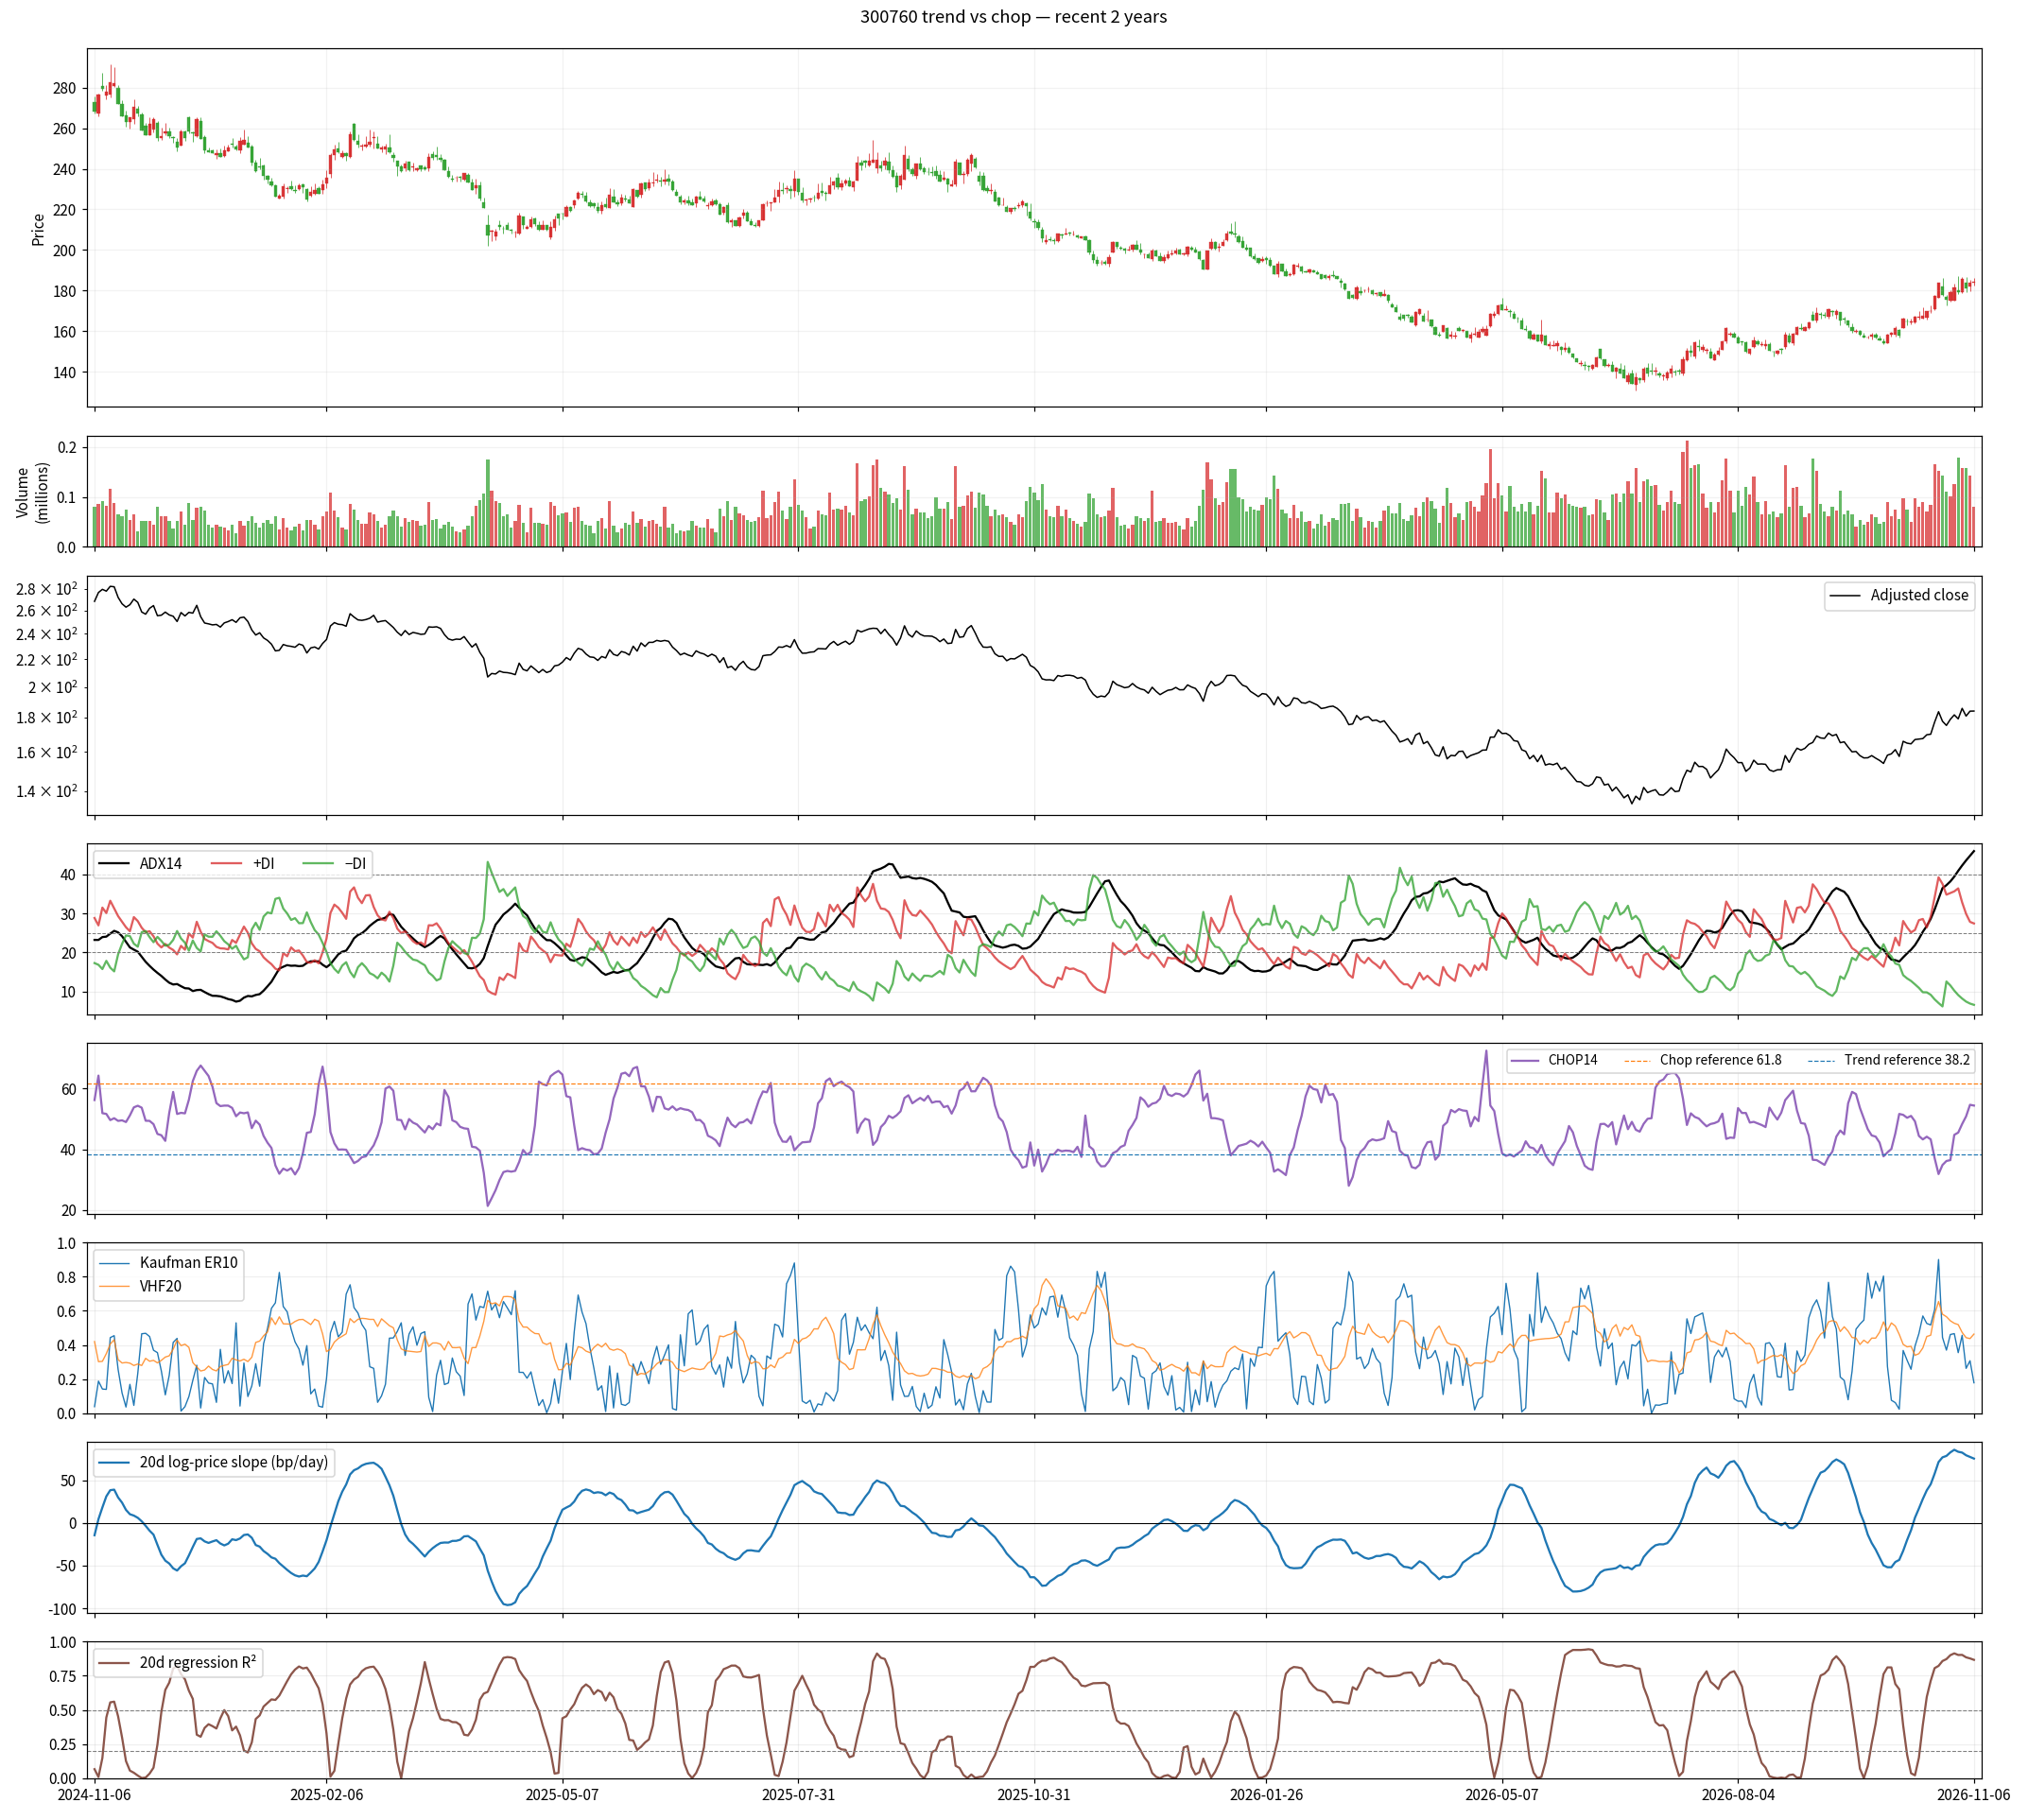

**趋势 / 震荡状态解读｜截至 2026-11-06**

- **ADX14：强趋势参考（45.95）。** < 20 为弱趋势参考，20—25 为过渡区，≥ 25 为有趋势参考，≥ 40 为强趋势参考；+DI > −DI，方向运动偏多（+DI 27.41 / −DI 6.55）。
- **CHOP14：趋势 / 震荡过渡区（54.43）。** > 61.8 偏震荡，< 38.2 偏趋势，中间区域不做单一状态判断。
- **路径效率：ER10 = 0.179，VHF20 = 0.464。** 越高表示价格路径越顺畅，越低表示来回噪声越多；两者都不提供涨跌方向，本面板不设固定判级阈值。
- **回归趋势：**20 日 log 收盘价斜率 +75.3 bp/day，方向上升；R² = 0.866，线性拟合质量较高（≥ 0.5 较高，0.2—0.5 中等，< 0.2 较低）。
- **综合解读：**ADX 与 CHOP 至少一项处于过渡区，暂不判为单一趋势或震荡状态；DI 与回归斜率的方向参考一致。R² 只衡量线性拟合质量，趋势 / 震荡状态也不直接映射仓位。

*以上为指标状态说明，经典阈值仅作观察参考，不构成独立交易信号。*

In [9]:
plot_state(recent, f'{STOCK_CODE} trend vs chop — recent {DISPLAY_YEARS} years')

## 6. 最新读数（不合成标签）

读数对应最后已入库交易日。解释列只是研究文档的通用含义，不能替代阈值标定和样本外验证。

In [10]:
latest = df.iloc[-1]
latest_date = latest['date']
rows = [
    ('收盘价', f"{latest['close']:.2f}", '前复权价格'),
    ('close / SMA200 − 1', f"{latest['close'] / latest['sma200'] - 1:+.2%}", '长期方向距离，不单独构成交易信号'),
    ('SMA200 20日斜率', f"{latest['sma200_slope20']:+.2%}", '长均线自身方向'),
    ('DIF / DEA', f"{latest['dif']:.3f} / {latest['dea']:.3f}", 'MACD 动量与零轴位置'),
    ('RSI14', f"{latest['rsi14']:.2f}", '50 为中轴；70/30 不是自动反转点'),
    ('ADX14', f"{latest['adx14']:.2f}", '趋势强度；20/25/40 为经典参考'),
    ('+DI / −DI', f"{latest['plus_di']:.2f} / {latest['minus_di']:.2f}", '方向运动对照'),
    ('CHOP14', f"{latest['chop14']:.2f}", '61.8/38.2 为震荡/趋势经典参考'),
    ('Kaufman ER10', f"{latest['er10']:.3f}", '净位移/路径长度，越高越顺畅'),
    ('VHF20', f"{latest['vhf20']:.3f}", '极值区间/路径长度，无方向'),
    ('回归斜率（年化）', f"{np.expm1(latest['reg_slope20'] * 252):+.2%}", '20日 log close OLS 斜率换算'),
    ('回归 R²', f"{latest['reg_r2_20']:.3f}", '趋势质量；0.2/0.5 为研究参考'),
    ('NATR14', f"{latest['natr14']:.2f}%", '相对价格波动'),
    ('BandWidth 126日分位', f"{latest['bb_width_rank126']:.1%}", '<10% 是 Squeeze 参考，不给方向'),
    ('MFI14', f"{latest['mfi14']:.2f}", '量价动量确认'),
    ('20日量比', f"{latest['volume_ratio20']:.2f}", '当日量/20日均量'),
]
latest_table = pd.DataFrame(rows, columns=['指标', '读数', '观察口径'])
print(f'最后交易日：{latest_date.date()}')
display(latest_table)

最后交易日：2026-11-06


,指标,读数,观察口径
0,收盘价,184.15,前复权价格
1,close / SMA200 − 1,+10.80%,长期方向距离，不单独构成交易信号
2,SMA200 20日斜率,-1.48%,长均线自身方向
3,DIF / DEA,5.791 / 5.062,MACD 动量与零轴位置
4,RSI14,64.24,50 为中轴；70/30 不是自动反转点
5,ADX14,45.95,趋势强度；20/25/40 为经典参考
6,+DI / −DI,27.41 / 6.55,方向运动对照
7,CHOP14,54.43,61.8/38.2 为震荡/趋势经典参考
8,Kaufman ER10,0.179,净位移/路径长度，越高越顺畅
9,VHF20,0.464,极值区间/路径长度，无方向


## 7. 观察记录与下一步

| 日期 | 图中现象 | 可证伪假设 | 需要的验证 | 状态 |
|---|---|---|---|---|
|  |  |  |  |  |
|  |  |  |  |  |
|  |  |  |  |  |

建议按顺序完善，每一步单独登记假设：

1. **阈值标定**：ADX/CHOP/ER 使用滚动历史分位数，检查窗口 ±20% 邻域，而不是先调阈值追求好看分段。
2. **市场宽度**：全 A 站上 MA200 占比、NH−NL、宽度背离；需要全市场截面，不能从比亚迪单股 OHLCV 推出。
3. **离线品种属性**：Hurst 与方差比只做长样本研究，不画短窗实时“状态”误导自己。
4. **迟滞与驻留状态机**：双阈值、最小驻留、切换次数统计；先固定规则再碰留出段。
5. **独立回测**：状态识别与执行分离，分别评估趋势策略和震荡策略被启用/关闭的时机。

第一版暂不包含 SAR/Supertrend 执行信号、期权/衍生品、HMM/聚类，也不把指标投票直接映射仓位。